In [1]:
###
import pandas as pd
from inclusion_financiere.config import RAW

df = pd.read_csv(RAW)
df.info()
df["bank_account"].value_counts(normalize=True)


<class 'pandas.DataFrame'>
RangeIndex: 23524 entries, 0 to 23523
Data columns (total 13 columns):
 #   Column                  Non-Null Count  Dtype
---  ------                  --------------  -----
 0   country                 23524 non-null  str  
 1   year                    23524 non-null  int64
 2   uniqueid                23524 non-null  str  
 3   bank_account            23524 non-null  str  
 4   location_type           23524 non-null  str  
 5   cellphone_access        23524 non-null  str  
 6   household_size          23524 non-null  int64
 7   age_of_respondent       23524 non-null  int64
 8   gender_of_respondent    23524 non-null  str  
 9   relationship_with_head  23524 non-null  str  
 10  marital_status          23524 non-null  str  
 11  education_level         23524 non-null  str  
 12  job_type                23524 non-null  str  
dtypes: int64(3), str(10)
memory usage: 2.3 MB


bank_account
No     0.859208
Yes    0.140792
Name: proportion, dtype: float64

In [2]:
print(df['bank_account'].value_counts(normalize=True) * 100)

bank_account
No     85.920762
Yes    14.079238
Name: proportion, dtype: float64


In [3]:
### 
df.groupby("country")["bank_account"].agg(["size", "nunique"])

,size,nunique
country,,
Kenya,6068,2
Rwanda,8735,2
Tanzania,6620,2
Uganda,2101,2


In [4]:
# Taux de bancarisation par pays
taux_pays = (
    df.groupby('country')['bank_account']
    .apply(lambda x: (x == 'Yes').mean() * 100)
    .reset_index(name='Taux_bancarisation')
)

print(taux_pays.round(2))

    country  Taux_bancarisation
0     Kenya               25.07
1    Rwanda               11.48
2  Tanzania                9.17
3    Uganda                8.61


In [5]:
## Croisez country et year avec pd.crosstab
pd.crosstab(df['country'], df['year'])

year,2016,2017,2018
country,,,
Kenya,0,0,6068
Rwanda,8735,0,0
Tanzania,0,6620,0
Uganda,0,0,2101


In [6]:
# Nombre total d'observations
print("Nombre total de lignes :", len(df))

# Nombre de valeurs uniques
print("Nombre de uniqueid distincts :", df['uniqueid'].nunique())

# Nombre de doublons
print("Nombre de doublons :", df['uniqueid'].duplicated().sum())

# Vérifier l'unicité
print("uniqueid est-il unique ?", df['uniqueid'].is_unique)

Nombre total de lignes : 23524
Nombre de uniqueid distincts : 8735
Nombre de doublons : 14789
uniqueid est-il unique ? False


In [7]:
df.groupby('country')['uniqueid'].agg(
    total='count',
    uniques='nunique'
)

,total,uniques
country,,
Kenya,6068,6068
Rwanda,8735,8735
Tanzania,6620,6620
Uganda,2101,2101


In [8]:
df.groupby('country')['uniqueid'].apply(
    lambda x: x.duplicated().sum()
)

country
Kenya       0
Rwanda      0
Tanzania    0
Uganda      0
Name: uniqueid, dtype: int64

In [9]:
print("Identifiants uniques :", df['uniqueid'].nunique())
print("Nombre de doublons :", df['uniqueid'].duplicated().sum())
print("Unicité globale :", df['uniqueid'].is_unique)

Identifiants uniques : 8735
Nombre de doublons : 14789
Unicité globale : False


In [10]:
# Définir la variable cible
target_col = 'bank_account'

# Exclure l'identifiant et la variable cible
features = [
    col for col in df.columns
    if col not in ['uniqueid', target_col]
]

# Identifier les profils présents au moins deux fois
mask_repeated = df.duplicated(
    subset=features,
    keep=False
)

# Nombre total de lignes appartenant à des profils répétés
print("Lignes partageant un profil répété :", mask_repeated.sum())

# Regrouper les observations ayant le même profil
groups = df.groupby(features, dropna=False)[target_col]

# Identifier les profils associés à plusieurs étiquettes
contradictory = groups.nunique(dropna=False) > 1

# Nombre de profils contradictoires
print("Nombre de profils contradictoires :", contradictory.sum())

# Nombre de lignes appartenant à ces profils contradictoires
contradictory_profiles = contradictory[contradictory].index

contradictory_rows = df.set_index(features).index.isin(
    contradictory_profiles
)

print("Lignes appartenant aux profils contradictoires :",
      contradictory_rows.sum())

Lignes partageant un profil répété : 7497
Nombre de profils contradictoires : 484
Lignes appartenant aux profils contradictoires : 1746


In [11]:
# Exemple : examiner les profils contradictoires
contradictory_data = df.loc[contradictory_rows]

pd.crosstab(
    contradictory_data['bank_account'],
    columns='Effectif'
)

col_0,Effectif
bank_account,
No,1196
Yes,550


In [12]:
contradictory_data = df.loc[contradictory_rows]

profile_labels = (
    contradictory_data
    .groupby(features)['bank_account']
    .value_counts()
    .unstack(fill_value=0)
)

profile_labels['total'] = (
    profile_labels['No'] + profile_labels['Yes']
)

profile_labels['erreur_minimale'] = (
    profile_labels[['No', 'Yes']].min(axis=1)
)

print(profile_labels.head())

print("Erreurs minimales théoriques :",
      profile_labels['erreur_minimale'].sum())

bank_account                                                                                                                                                                      No  \
country year location_type cellphone_access household_size age_of_respondent gender_of_respondent relationship_with_head marital_status education_level     job_type                   
Kenya   2018 Rural         No               1              68                Female               Head of Household      Widowed        No formal education Farming and Fishing    1   
                                                           70                Female               Head of Household      Widowed        No formal education Other Income           1   
                                                           80                Female               Head of Household      Widowed        No formal education Remittance Dependent   1   
                                                           86                Fem

In [13]:
# Identifier les variables catégorielles
cat_cols = df.select_dtypes(
    include=['object', 'category']
).columns.tolist()

# Exclure les identifiants et la variable cible
cat_cols = [
    col for col in cat_cols
    if col not in ['uniqueid', 'bank_account']
]

# Rechercher les modalités ayant moins de 50 occurrences
modalites_rares = []

for col in cat_cols:
    counts = df[col].value_counts(dropna=False)

    for modalite, effectif in counts.items():
        if effectif < 50:
            modalites_rares.append({
                'Variable': col,
                'Modalité': modalite,
                'Effectif': effectif
            })

# Afficher les résultats
rares_df = pd.DataFrame(modalites_rares)

print("Nombre de modalités rares :", len(rares_df))
display(rares_df.sort_values('Effectif'))

Nombre de modalités rares : 2


C:\Users\hp\AppData\Local\Temp\ipykernel_21568\1375352828.py:2: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/dev/user_guide/migration.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  cat_cols = df.select_dtypes(


,Variable,Modalité,Effectif
0,marital_status,Dont know,8
1,education_level,Other/Dont know/RTA,35


In [14]:
import pandas as pd
import matplotlib.pyplot as plt

# Variables à analyser
variables = ['education_level', 'job_type', 'cellphone_access']

# Vérifier les taux de bancarisation
for var in variables:
    taux = (
        df.groupby(var, dropna=False)['bank_account']
        .apply(lambda x: (x == 'Yes').mean() * 100)
        .sort_values(ascending=False)
    )

    print(f"\nTaux de bancarisation selon {var} :")
    print(taux.round(2))


Taux de bancarisation selon education_level :
education_level
Vocational/Specialised training    57.04
Tertiary education                 51.08
Other/Dont know/RTA                31.43
Secondary education                23.28
Primary education                   8.55
No formal education                 3.90
Name: bank_account, dtype: float64

Taux de bancarisation selon job_type :
job_type
Formally employed Government    77.52
Formally employed Private       54.12
Government Dependent            20.24
Other Income                    18.15
Self employed                   13.17
Farming and Fishing             11.67
Dont Know/Refuse to answer      11.11
Remittance Dependent             9.50
Informally employed              7.95
No Income                        2.07
Name: bank_account, dtype: float64

Taux de bancarisation selon cellphone_access :
cellphone_access
Yes    18.38
No      1.71
Name: bank_account, dtype: float64


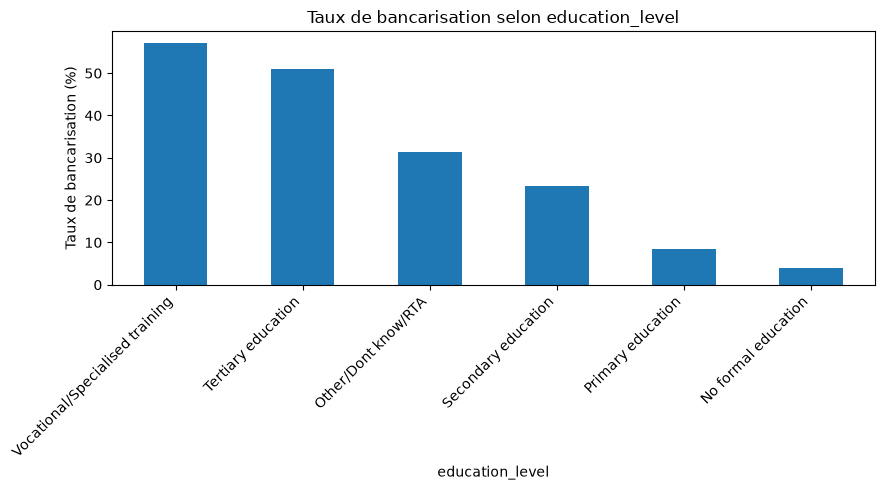

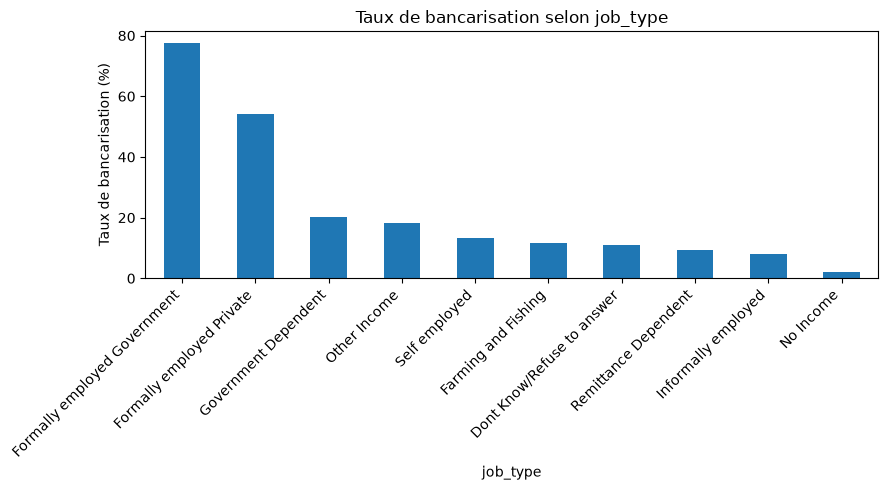

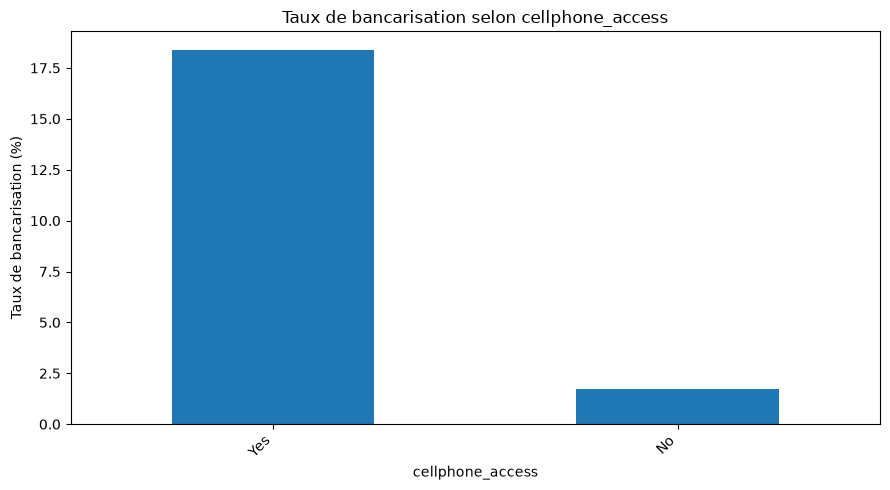

In [15]:
for var in variables:

    taux = (
        df.groupby(var, dropna=False)['bank_account']
        .apply(lambda x: (x == 'Yes').mean() * 100)
        .sort_values(ascending=False)
    )

    plt.figure(figsize=(9, 5))

    taux.plot(kind='bar')

    plt.title(f'Taux de bancarisation selon {var}')
    plt.xlabel(var)
    plt.ylabel('Taux de bancarisation (%)')
    plt.xticks(rotation=45, ha='right')
    plt.tight_layout()
    plt.show()